# VaR / ES with GARCH and Backtesting (R)

A VaR model is only as good as its record, and regulators judge that record by counting the days the model was wrong. This notebook estimates daily VaR and Expected Shortfall for a multi-asset portfolio with five models, from plain history to GARCH with skewed tails, and shows exactly where and when each one fails.

**What it does.** It estimates the 1-day 99% Value-at-Risk and 97.5% Expected Shortfall of a five-ETF multi-asset portfolio every day since 2011 with five models, from historical simulation to GJR-GARCH with skewed Student-t errors, all re-estimated on a rolling 1,000-day window.

Every model is backtested with the Kupiec, Christoffersen and McNeil–Frey tests and the Basel traffic light, and the notebook shows where each one fails: 2020, 2022 and the recent past.

**Data.** Daily adjusted prices of SPY, EFA, TLT, LQD and GLD since 2007 (Yahoo Finance via `quantmod`).

**Methods.** Historical simulation, RiskMetrics EWMA, GARCH(1,1) with normal and Student-t errors, GJR-GARCH(1,1) with skewed-t errors (`rugarch::ugarchroll`) and filtered historical simulation.

The backtests are the unconditional and conditional coverage tests (`VaRTest`), the ES test (`ESTest`) and rolling 250-day Basel traffic-light zones, with `PerformanceAnalytics` for the portfolio returns.

**Key output.** VaR and ES paths with their exceedances, a backtest scorecard, the traffic-light history and an interactive dashboard.

## 1. Why backtest VaR

A VaR model is only as good as its record. Under the Basel market-risk framework the 99% VaR is backtested on the last 250 days. With 0–4 exceptions the model is in the **green** zone, with 5–9 **yellow** (capital multiplier raised) and with 10 or more **red** (the model must be replaced). The 2019 FRTB rules moved the capital measure to the 97.5% Expected Shortfall, which also needs backtesting.

Three questions, each with a test:

1. **Coverage:** is the share of exceptions close to 1%? (Kupiec's proportion-of-failures test)
2. **Independence:** do exceptions cluster in time? A model that misses several days in a row reacts too slowly. (Christoffersen's test; the conditional-coverage test combines the two.)
3. **Severity:** when VaR is breached, is the loss as large as the ES says? (McNeil and Frey's test on standardised exceedance residuals.)

R has mature tools for all of this: `rugarch` for GARCH estimation, rolling forecasts and the tests, and `PerformanceAnalytics` for portfolio returns.

## 2. Setup

In [1]:
# --- Packages (install once with `Rscript install_packages.R` from the repo
# root)
suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(patchwork)
  library(plotly)
  library(htmlwidgets)
  library(jsonlite)
})
options(warn = 1, dplyr.summarise.inform = FALSE, repr.plot.width = 14,
        repr.plot.height = 5, repr.plot.res = 110)
# plain-text tables in the notebook (no ANSI colour codes)
options(crayon.enabled = FALSE, cli.num_colors = 1)

# --- Folders and credentials
PROJECT_DIR <- getwd()
DATA_DIR <- file.path(PROJECT_DIR,
                      "data"); OUT_DIR <- file.path(PROJECT_DIR, "outputs")
dir.create(DATA_DIR,
           showWarnings = FALSE); dir.create(OUT_DIR, showWarnings = FALSE)
# look for .env in this folder and its parents (like python-dotenv)
find_env <- function(start = getwd()) {
  d <- normalizePath(start)
  repeat {
    f <- file.path(d, ".env")
    if (file.exists(f)) return(f)
    parent <- dirname(d)
    if (parent == d) return(NA_character_)
    d <- parent
  }
}
env_file <- find_env()
# tolerate a missing final newline
if (!is.na(env_file)) suppressWarnings(dotenv::load_dot_env(env_file))

# --- Cache helper: every download is stored in data/ and reused for 12 hours
cached <- function(name, fetch, max_age_hours = 12) {
  path <- file.path(DATA_DIR, paste0(name, ".rds"))
  if (file.exists(path) &&
      difftime(Sys.time(), file.mtime(path),
               units = "hours") < max_age_hours) return(readRDS(path))
  out <- tryCatch(fetch(), error = function(e) {
    if (file.exists(path)) { message(name, ": download failed (",
                                     conditionMessage(e),
                                     "); using cached copy"); return(readRDS(path)) }
    stop(e)
  })
  saveRDS(out, path)
  out
}

# --- Chart style (consistent palette across all charts)
PALETTE <- c("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300",
             "#6250d6", "#e34948")
INK <- "#0b0b0b"; INK_2 <- "#52514e"; GRID <- "#e4e3df"; SURFACE <- "#fcfcfb"
STATUS <- c(green = "#1baf7a", amber = "#eda100", red = "#e34948")
theme_risk <- function() {
  theme_minimal(base_size = 11) +
    theme(plot.background = element_rect(fill = SURFACE, colour = NA),
          panel.background = element_rect(fill = SURFACE, colour = NA),
          panel.grid.major = element_line(colour = GRID),
            panel.grid.minor = element_blank(),
          plot.title = element_text(face = "bold", colour = INK, size = 12),
            plot.title.position = "plot",
          axis.text = element_text(colour = INK_2),
            axis.title = element_text(colour = INK_2),
          legend.position = "top", legend.title = element_blank())
}
theme_set(theme_risk())
save_fig <- function(p, name, width = 14,
                     height = 5) ggsave(file.path(
                         OUT_DIR, paste0(name, ".png")),
                                        p, width = width, height = height,
                                        dpi = 150, bg = SURFACE)

# Interactive dashboard as a single HTML file that loads plotly.js from a CDN
# (no pandoc needed)
save_plotly_html <- function(widget, name, title) {
  b <- plotly_build(widget)$x
  if (is.null(b$layout$height)) b$layout$height <- 900
  html <- sprintf('<!doctype html><html><head><meta charset="utf-8"><title>%s</title>
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script></head>
<body style="background:%s;margin:0"><div id="dash" style="width:100%%;height:95vh"></div>
<script>var fig=%s;Plotly.newPlot("dash",fig.data,fig.layout,{responsive:true});</script></body></html>',
                  title, SURFACE,
                    toJSON(list(data = b$data, layout = b$layout),
                           auto_unbox = TRUE, null = "null", na = "null",
                           force = TRUE, digits = NA))
  writeLines(html, file.path(OUT_DIR, paste0(name, ".html")))
  message("Dashboard saved: outputs/", name, ".html")
}

suppressPackageStartupMessages({
  library(quantmod)
  library(xts)
  library(rugarch)
  library(PerformanceAnalytics)
})
TICKERS <- c("SPY", "EFA", "TLT", "LQD", "GLD")
WEIGHTS <- c(SPY = 0.35, EFA = 0.15, TLT = 0.20, LQD = 0.20, GLD = 0.10)
START <- "2007-01-01"
WINDOW <- 1000           # estimation window (days)
REFIT <- 25              # re-estimate every 25 days
ALPHA_VAR <- 0.01; ALPHA_ES <- 0.025
set.seed(11)
cat(sprintf("R %s · rugarch %s · PerformanceAnalytics %s · run on %s\n",
            getRversion(), packageVersion("rugarch"),
            packageVersion("PerformanceAnalytics"), Sys.Date()))

R 4.3.3 · rugarch 1.5.6 · PerformanceAnalytics 2.1.0 · run on 2026-10-19


## 3. Data and portfolio returns

In [2]:
prices <- cached("yahoo_prices", function() {
  do.call(
    merge,
    lapply(
      TICKERS,
      function(t) Ad(getSymbols(
        t,
        src = "yahoo", from = START, auto.assign = FALSE
      ))
    )
  )
})
colnames(prices) <- TICKERS
prices <- na.locf(prices[index(prices) < Sys.Date()])
# the first row is NA by construction
rets <- na.omit(suppressWarnings(Return.calculate(prices, method = "log")))
# Daily-rebalanced portfolio (constant weights), log return
simple <- exp(rets) - 1
# internal log(1+x) on the empty start row
port_simple <- suppressWarnings(Return.portfolio(
  simple,
  weights = WEIGHTS, rebalance_on = "days"
))
port <- xts(log(1 + as.numeric(port_simple)), index(rets))
stopifnot(!anyNA(port))
colnames(port) <- "portfolio"
cat(sprintf(
  "%s trading days · %s → %s\n", nrow(port), format(start(port)),
  format(end(port))
))
round(
  suppressWarnings(table.Stats(port * 100))[
      c("Observations", "Arithmetic Mean", "Stdev", "Skewness", "Kurtosis",
        "Minimum", "Maximum"),
      , drop = FALSE],
  3
)

4978 trading days · 2007-01-04 → 2026-10-16


,portfolio
,<dbl>
Observations,4978.000
Arithmetic Mean,0.030
Stdev,0.670
Skewness,-0.046
Kurtosis,14.147
Minimum,-6.429
Maximum,7.846


## 4. Five VaR / ES models, re-estimated on a rolling window

| Model | VaR / ES |
|---|---|
| **Historical simulation (HS)** | empirical 1% quantile and 2.5% tail mean of the last 1,000 returns |
| **RiskMetrics EWMA** | $\sigma_t^2 = 0.94\,\sigma_{t-1}^2 + 0.06\,r_{t-1}^2$, normal quantile |
| **GARCH(1,1) normal** | `ugarchroll`, refitted every 25 days |
| **GARCH(1,1) Student-t** | same, with fat-tailed errors |
| **GJR-GARCH skew-t** | asymmetric volatility (bad news raises vol more) and skewed fat tails |
| **Filtered HS (FHS)** | GJR-GARCH volatility × empirical quantile of the standardised residuals |

VaR and ES are reported as positive losses in % of portfolio value. ES at 97.5% for the parametric models is computed by integrating the fitted conditional quantile function.

In [3]:
r <- as.numeric(port) * 100
dates <- index(port)
n <- length(r)
oos <- (WINDOW + 1):n

# Historical simulation
hs_var <- sapply(oos,
                 function(i) -quantile(r[(i - WINDOW):(i - 1)], ALPHA_VAR,
                                       names = FALSE))
hs_es <- sapply(oos, function(i) {
  w <- r[(i - WINDOW):(i - 1)]; -mean(w[w <= quantile(w, ALPHA_ES)])
})
hs_v25 <- sapply(oos,
                 function(i) -quantile(r[(i - WINDOW):(i - 1)], ALPHA_ES,
                                       names = FALSE))

# RiskMetrics EWMA
s2 <- numeric(n); s2[1] <- var(r[1:250])
for (t in 2:n) s2[t] <- 0.94 * s2[t - 1] + 0.06 * r[t - 1]^2
ew_var <- -qnorm(ALPHA_VAR) * sqrt(s2[oos])
ew_es <- dnorm(qnorm(ALPHA_ES)) / ALPHA_ES * sqrt(s2[oos])
ew_v25 <- -qnorm(ALPHA_ES) * sqrt(s2[oos])

spec_of <- function(model, dist) ugarchspec(
  variance.model = list(model = model, garchOrder = c(1, 1)),
  mean.model = list(armaOrder = c(0, 0), include.mean = TRUE),
  distribution.model = dist
)
roll_model <- function(model, dist) {
  ugarchroll(spec_of(model, dist),
    data = port * 100, n.ahead = 1, forecast.length = length(oos),
      refit.every = REFIT,
    refit.window = "moving", window.size = WINDOW, solver = "hybrid",
      calculate.VaR = TRUE,
    VaR.alpha = c(ALPHA_VAR, ALPHA_ES), keep.coef = TRUE
  )
}
es_from_roll <- function(roll, alpha = ALPHA_ES) {
  d <- as.data.frame(roll) # Mu, Sigma, Skew, Shape, Shape(GIG), Realized
  dist <- roll@model$spec@model$modeldesc$distribution
  sapply(seq_len(nrow(d)), function(i) {
    f <- function(p) qdist(dist, p, mu = d$Mu[i], sigma = d$Sigma[i],
                           skew = d$Skew[i], shape = d$Shape[i])
    -integrate(f, 1e-6, alpha, subdivisions = 200)$value / alpha
  })
}
t0 <- Sys.time()
rolls <- list(
  `GARCH normal` = roll_model("sGARCH", "norm"),
    `GARCH Student-t` = roll_model("sGARCH", "std"),
  `GJR-GARCH skew-t` = roll_model("gjrGARCH", "sstd")
)
cat(sprintf("Rolling GARCH forecasts: %d days × 3 models in %.0f s\n",
            length(oos), as.numeric(difftime(Sys.time(), t0, units = "secs"))))

var_mat <- data.frame(`Historical simulation` = hs_var,
                      `RiskMetrics EWMA` = ew_var, check.names = FALSE)
es_mat <- data.frame(`Historical simulation` = hs_es,
                     `RiskMetrics EWMA` = ew_es, check.names = FALSE)
# 97.5% VaR, for the ES test
v25_mat <- data.frame(`Historical simulation` = hs_v25,
                      `RiskMetrics EWMA` = ew_v25, check.names = FALSE)
for (m in names(rolls)) {
  v <- as.data.frame(rolls[[m]], which = "VaR")
  # columns are alpha(1%) and alpha(2.5%) (printed as "alpha(3%)"), then
  # realized
  var_mat[[m]] <- -v[[1]]
  v25_mat[[m]] <- -v[[2]]
  es_mat[[m]] <- es_from_roll(rolls[[m]])
}
# Filtered historical simulation on the GJR-GARCH skew-t volatility
gj <- as.data.frame(rolls[["GJR-GARCH skew-t"]])
z <- (r[oos] - gj$Mu) / gj$Sigma
fhs <- sapply(seq_along(oos), function(k) {
  zz <- z[max(1, k - WINDOW):max(1, k - 1)]
  if (length(zz) < 250) zz <- (r[(oos[k] - WINDOW):(oos[k] - 1)] -
                               mean(r[(oos[k] - WINDOW):(oos[k] - 1)])) /
    sd(r[(oos[k] - WINDOW):(oos[k] - 1)])
  q <- quantile(zz, ALPHA_VAR, names = FALSE); qe <- quantile(zz, ALPHA_ES,
                names = FALSE)
  c(-(gj$Mu[k] + gj$Sigma[k] * q),
    -(gj$Mu[k] + gj$Sigma[k] * mean(zz[zz <= qe])),
    -(gj$Mu[k] + gj$Sigma[k] * qe))
})
var_mat[["Filtered HS"]] <- fhs[1, ]; es_mat[["Filtered HS"]] <- fhs[2,
                                ]; v25_mat[["Filtered HS"]] <- fhs[3, ]
MODELS <- names(var_mat)
MODEL_COLORS <- setNames(PALETTE[c(8, 4, 1, 3, 2, 7)], MODELS)
realised <- r[oos]; oos_dates <- dates[oos]
cat(sprintf("Out-of-sample: %s → %s (%d days)\n", format(min(oos_dates)),
            format(max(oos_dates)), length(oos)))

Rolling GARCH forecasts: 3978 days × 3 models in 123 s


Out-of-sample: 2010-12-22 → 2026-10-16 (3978 days)


## 5. Backtests

- **Kupiec (unconditional coverage)** and **Christoffersen (conditional coverage)** from `rugarch::VaRTest`, at the 1% level.
- **McNeil–Frey ES test** from `rugarch::ESTest`, at 97.5%: on the days the 97.5% VaR is breached, the excess of the loss over the ES should average zero; a significant positive excess means ES understates tail losses.
- **Basel traffic light:** for every day, the number of exceptions in the trailing 250 days; the share of days in the yellow and red zones.

In [4]:
bt <- map_dfr(MODELS, function(m) {
  v <- var_mat[[m]]; e <- es_mat[[m]]
  hit <- realised < -v
  vt <- VaRTest(
    alpha = ALPHA_VAR, actual = realised, VaR = -v,
    conf.level = 0.95
  )
  et <- tryCatch(ESTest(alpha = ALPHA_ES, actual = realised, ES = -e,
                        VaR = -v25_mat[[m]], conf.level = 0.95, boot = TRUE,
                        n.boot = 1000),
    error = function(err) list(p.value = NA_real_)
  )
  roll_exc <- stats::filter(as.numeric(hit), rep(1, 250), sides = 1)
  tibble(
    model = m, `exceptions` = sum(hit),
    `expected` = round(ALPHA_VAR * length(hit), 1),
    `exception rate %` = mean(hit) * 100,
    `Kupiec p` = vt$uc.LRp, `Christoffersen CC p` = vt$cc.LRp,
    `ES test p` = et$p.value,
    `avg VaR %` = mean(v), `avg ES 97.5% %` = mean(e),
    `days in yellow %` = mean(roll_exc >= 5 & roll_exc <= 9, na.rm = TRUE) *
      100,
    `days in red %` = mean(roll_exc >= 10, na.rm = TRUE) * 100,
    `max 250d exceptions` = max(roll_exc, na.rm = TRUE)
  )
})
bt %>% mutate(across(where(is.numeric), ~ round(.x, 3)))

model,exceptions,expected,exception rate %,Kupiec p,Christoffersen CC p,ES test p,avg VaR %,avg ES 97.5% %,days in yellow %,days in red %,max 250d exceptions
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Historical simulation,38,39.8,0.955,0.775,0.000,0.865,1.634,1.810,7.187,4.907,12
RiskMetrics EWMA,80,39.8,2.011,0.000,0.000,0.000,1.233,1.239,59.560,1.019,11
GARCH normal,76,39.8,1.911,0.000,0.000,0.000,1.210,1.216,33.950,10.566,12
GARCH Student-t,60,39.8,1.508,0.003,0.000,0.004,1.306,1.344,27.460,3.111,11
GJR-GARCH skew-t,48,39.8,1.207,0.205,0.005,0.031,1.416,1.454,13.194,0.429,10
Filtered HS,46,39.8,1.156,0.333,0.000,0.523,1.480,1.552,15.581,3.111,11


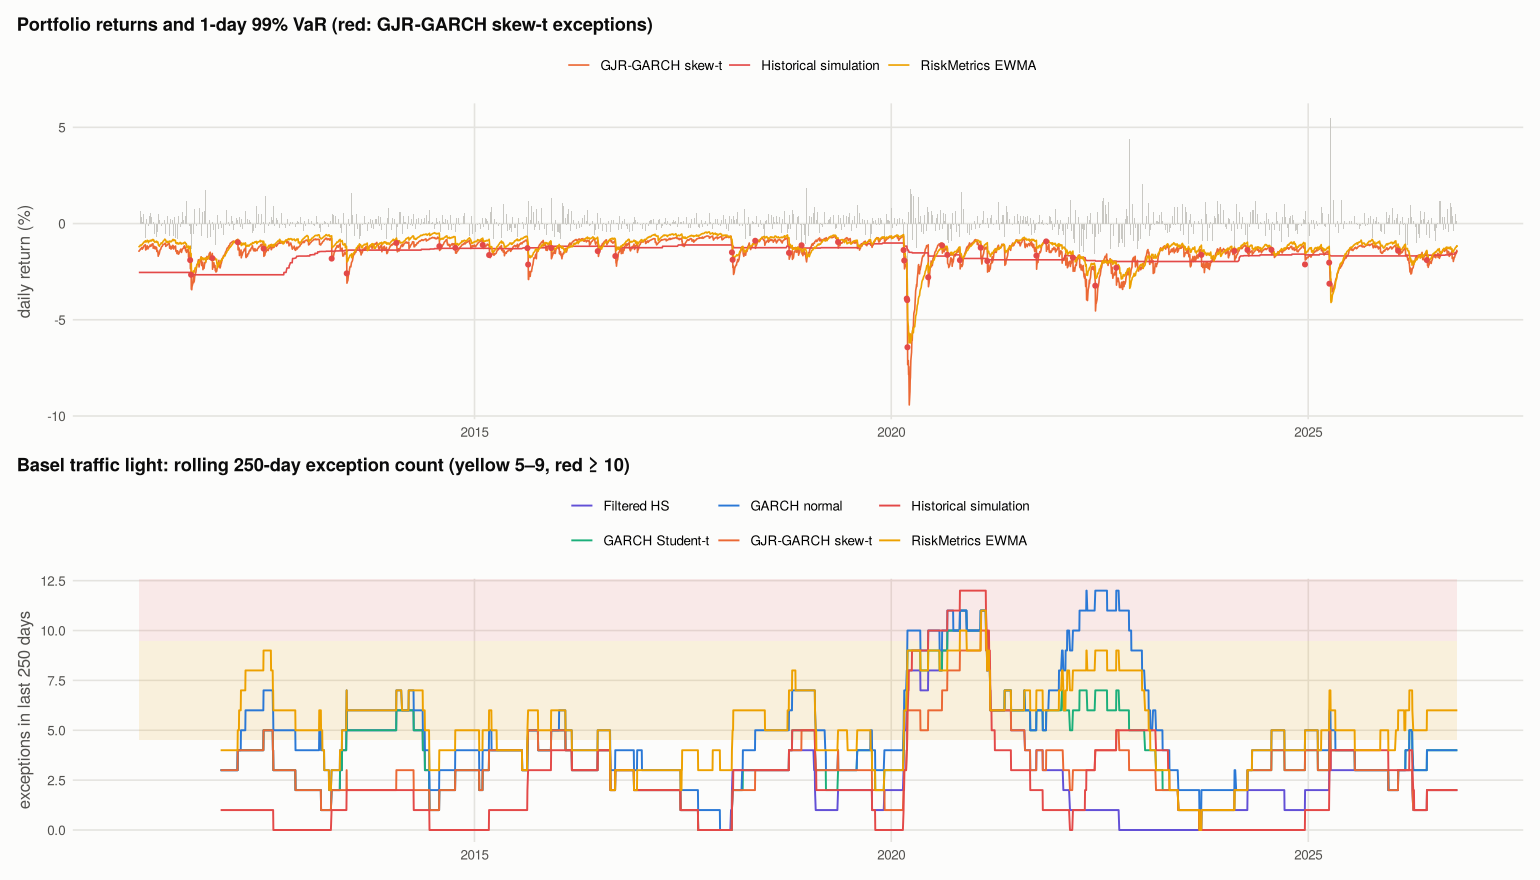

In [5]:
# --- Chart 1: returns vs VaR, and the 250-day exception count
plot_df <- tibble(date = oos_dates, ret = realised) %>%
  bind_cols(var_mat %>% rename_with(~ paste0("VaR_", .x)))
long <- plot_df %>%
  pivot_longer(starts_with("VaR_"), names_to = "model", values_to = "VaR") %>%
  mutate(model = sub("VaR_", "", model))
exc <- long %>% filter(model == "GJR-GARCH skew-t", ret < -VaR)
p1 <- ggplot(plot_df, aes(date, ret)) +
  geom_col(width = 1, fill = "#c9c8c3") +
  geom_line(
    data = long %>%
      filter(model %in%
             c("Historical simulation", "RiskMetrics EWMA",
               "GJR-GARCH skew-t")),
    aes(date, -VaR, colour = model), linewidth = 0.5
  ) +
  geom_point(data = exc, aes(date, ret), colour = STATUS[["red"]],
             size = 1.2) +
  scale_colour_manual(values = MODEL_COLORS) +
  labs(
    x = NULL, y = "daily return (%)",
    title = "Portfolio returns and 1-day 99% VaR (red: GJR-GARCH skew-t exceptions)"
  )
roll_df <- map_dfr(MODELS, function(m) tibble(
  date = oos_dates, model = m,
  exc = as.numeric(stats::filter(as.numeric(realised < -var_mat[[m]]),
                                 rep(1, 250), sides = 1))
))
p2 <- ggplot(roll_df, aes(date, exc, colour = model)) +
  annotate("rect", xmin = min(oos_dates), xmax = max(oos_dates), ymin = 4.5,
           ymax = 9.5, fill = STATUS[["amber"]], alpha = 0.12) +
  annotate("rect", xmin = min(oos_dates), xmax = max(oos_dates), ymin = 9.5,
           ymax = Inf, fill = STATUS[["red"]], alpha = 0.10) +
  geom_line(linewidth = 0.6, na.rm = TRUE) +
  scale_colour_manual(values = MODEL_COLORS) +
  labs(x = NULL, y = "exceptions in last 250 days",
       title = "Basel traffic light: rolling 250-day exception count (yellow 5–9, red ≥ 10)")
fig1 <- p1 / p2 + plot_layout(heights = c(1.2, 1))
save_fig(fig1, "01_var_paths_traffic_light", height = 8)
options(repr.plot.height = 8); print(fig1); options(repr.plot.height = 5)

## 6. Where the models fail: stress windows

The exception count and the average ratio of realised loss to VaR on exception days, in three windows: the COVID crash (February–April 2020), the 2022 rate shock (when stocks and long bonds fell together) and the last 12 months.

In [6]:
windows <- list(
  `COVID crash (Feb–Apr 2020)` = c("2020-02-15", "2020-04-30"),
  `2022 rate shock` = c("2022-01-01", "2022-12-31"),
  `Last 12 months` = c(format(max(oos_dates) - 365), format(max(oos_dates)))
)
stress <- map_dfr(names(windows), function(w) {
  idx <- oos_dates >= as.Date(windows[[w]][1]) &
    oos_dates <= as.Date(windows[[w]][2])
  map_dfr(MODELS, function(m) {
    v <- var_mat[[m]][idx]; x <- realised[idx]; hit <- x < -v
    tibble(
      window = w, model = m, days = sum(idx), exceptions = sum(hit),
      `loss / VaR on exception days` = if (any(hit)) mean(
        -x[hit] / v[hit]
      ) else NA_real_
    )
  })
})
stress %>%
  pivot_wider(id_cols = model, names_from = window, values_from = exceptions)

model,COVID crash (Feb–Apr 2020),2022 rate shock,Last 12 months
<chr>,<int>,<int>,<int>
Historical simulation,9,5,2
RiskMetrics EWMA,6,8,6
GARCH normal,6,9,4
GARCH Student-t,6,5,4
GJR-GARCH skew-t,5,3,2
Filtered HS,6,0,2


## 7. Results dashboard

Dashboard saved: outputs/dashboard.html



Outputs: 01_var_paths_traffic_light.png, dashboard.html, dashboard.png, backtest_scorecard.csv, stress_window_exceptions.csv, var_es_paths.csv 


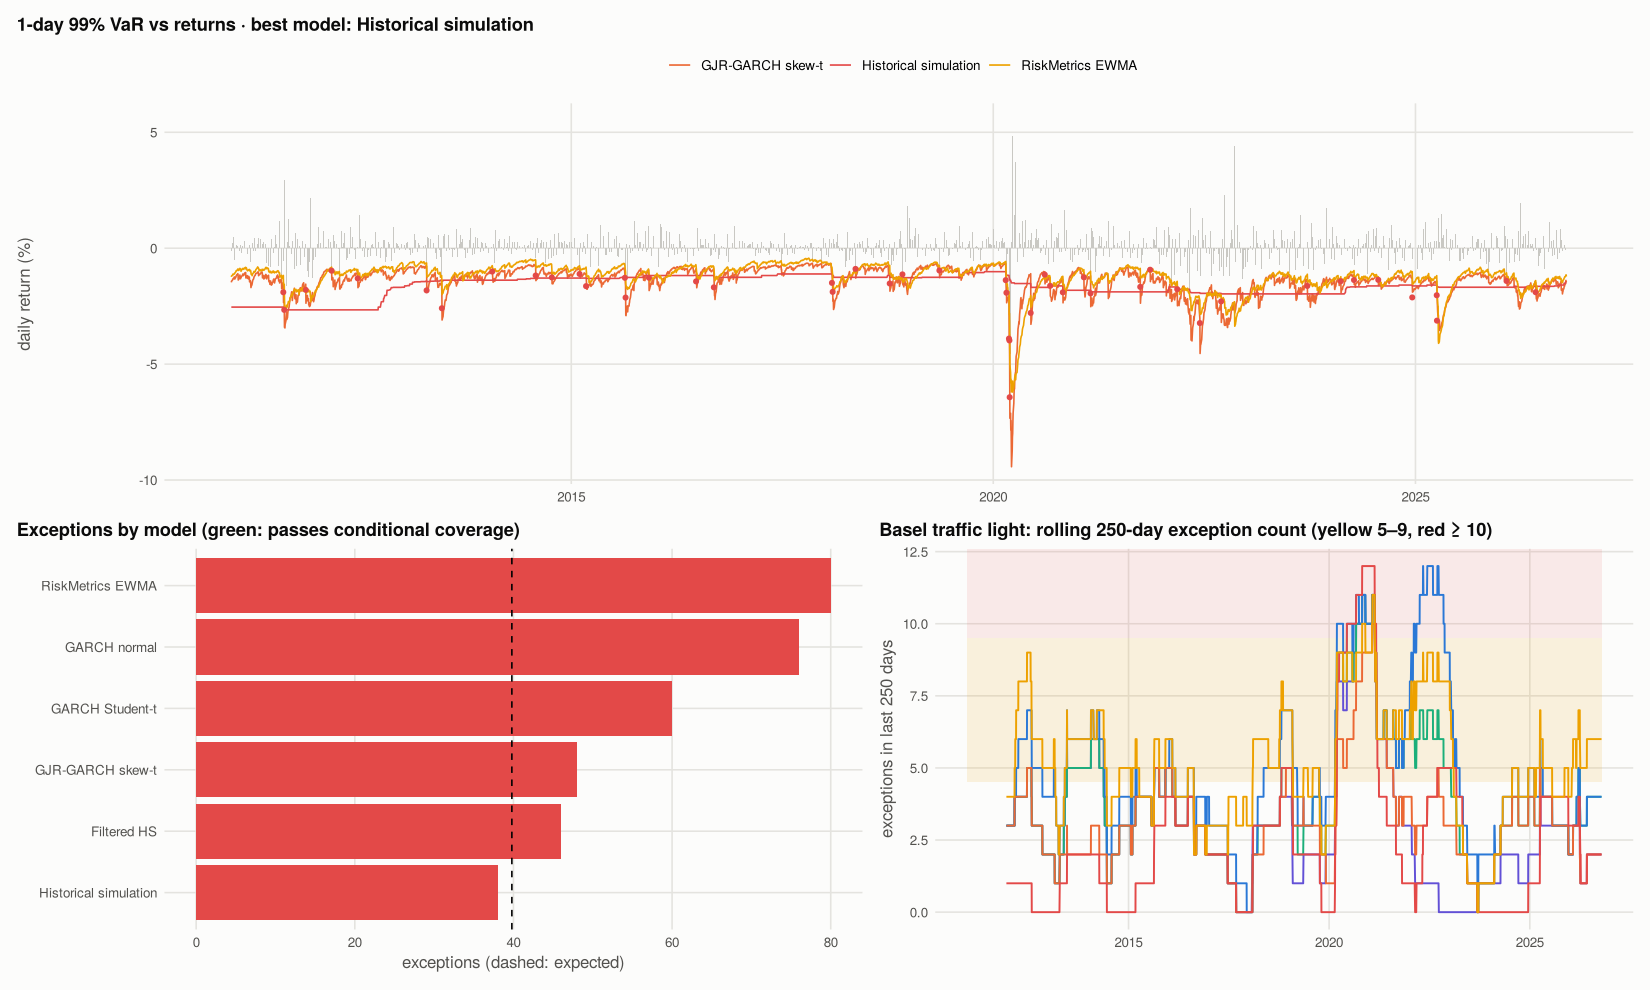

In [7]:
best <- bt %>%
  filter(`Christoffersen CC p` > 0.05) %>%
  arrange(desc(`ES test p`)) %>%
  slice(1) %>%
  pull(model)
if (length(best) == 0) best <- bt %>%
  arrange(abs(`exception rate %` - 1)) %>%
  slice(1) %>%
  pull(model)
light <- function(p) ifelse(is.na(p), INK_2,
  ifelse(p < 0.01, STATUS[["red"]],
    ifelse(
      p < 0.05, STATUS[["amber"]],
      STATUS[["green"]]
    )
  )
)
pl1 <- plot_ly(plot_df, x = ~date) %>%
  add_bars(
    y = ~ret, name = "daily return",
    marker = list(color = "#c9c8c3")
  ) %>%
  add_lines(
    y = ~ -`VaR_GJR-GARCH skew-t`, name = "VaR GJR-GARCH skew-t",
    line = list(color = MODEL_COLORS[["GJR-GARCH skew-t"]])
  ) %>%
  add_lines(
    y = ~ -`VaR_Historical simulation`,
    name = "VaR historical simulation",
    line = list(color = MODEL_COLORS[["Historical simulation"]])
  ) %>%
  add_lines(
    y = ~ -`VaR_RiskMetrics EWMA`, name = "VaR EWMA",
    line = list(color = MODEL_COLORS[["RiskMetrics EWMA"]])
  )
pl2 <- plot_ly(bt,
  x = ~model, y = ~`exceptions`, type = "bar", name = "exceptions",
  marker = list(color = light(bt$`Christoffersen CC p`)),
  text = ~ round(`exception rate %`, 2), textposition = "outside"
) %>%
  add_lines(
    x = ~model, y = ~expected, name = "expected (1%)",
    line = list(color = INK, dash = "dash"), inherit = FALSE
  )
pl3 <- plot_ly(roll_df,
  x = ~date, y = ~exc, color = ~model,
  colors = MODEL_COLORS, type = "scatter", mode = "lines",
  showlegend = FALSE
)
dash <- subplot(pl1,
  subplot(pl2, pl3, nrows = 1, widths = c(0.4, 0.6), titleY = TRUE),
  nrows = 2, heights = c(0.5, 0.5),
  margin = 0.07, titleY = TRUE
) %>%
  layout(
    title = list(x = 0.01, text = sprintf(
      "<b>VaR / ES backtest · 5-ETF portfolio, %s – %s</b><br><span style='font-size:13px'>%d days · best model: %s · bars coloured by Christoffersen p-value (green > 5%%)</span>",
      format(min(oos_dates), "%b %Y"), format(max(oos_dates), "%b %Y"),
      length(oos), best
    )),
    paper_bgcolor = SURFACE, plot_bgcolor = SURFACE, margin = list(t = 110),
    legend = list(orientation = "h", y = -0.05)
  )
save_plotly_html(dash, "dashboard", "VaR / ES backtest")
dash_png <- (p1 +
  labs(title = sprintf(
    "1-day 99%% VaR vs returns · best model: %s",
    best
  ))) /
  (ggplot(
    bt,
    aes(reorder(model, exceptions), exceptions,
      fill = light(`Christoffersen CC p`)
    )
  ) +
    geom_col() +
    scale_fill_identity() +
    geom_hline(yintercept = bt$expected[1], linetype = "dashed") +
    coord_flip() +
    labs(
      x = NULL, y = "exceptions (dashed: expected)",
      title = "Exceptions by model (green: passes conditional coverage)"
    ) | p2 + theme(legend.position = "none")) +
  plot_layout(heights = c(1, 1))
save_fig(dash_png, "dashboard", width = 15, height = 9)
options(repr.plot.width = 15, repr.plot.height = 9)
print(dash_png) # the static dashboard, shown here as well as saved
write_csv(bt, file.path(OUT_DIR, "backtest_scorecard.csv"))
write_csv(stress, file.path(OUT_DIR, "stress_window_exceptions.csv"))
write_csv(bind_cols(
  tibble(date = oos_dates, return = realised), var_mat %>%
    rename_with(~ paste0("VaR99 ", .x)),
  es_mat %>% rename_with(~ paste0("ES97.5 ", .x))
), file.path(OUT_DIR, "var_es_paths.csv"))
cat("Outputs:", paste(list.files(OUT_DIR), collapse = ", "), "\n")

## 8. Reading the results and limitations

Five-ETF portfolio (35% SPY, 15% EFA, 20% TLT, 20% LQD, 10% GLD), 1-day 99% VaR and 97.5% ES, December 2010 – October 2026 (3,978 out-of-sample days, about 40 exceptions expected):

**Coverage alone is not enough.** Historical simulation has almost exactly the right number of exceptions (38, Kupiec p = 0.78) and its ES passes the McNeil–Frey test (p = 0.87). It still fails conditional coverage badly (p = 0.0001): its exceptions arrive in clusters because a 1,000-day window reacts slowly.

It spent 4.9% of days in the Basel red zone, peaking at 12 exceptions in 250 days around the COVID crash, where it was hit 9 times in 52 days with losses averaging 2.6 times VaR.

- **Thin tails fail.** RiskMetrics EWMA and GARCH with normal errors have about twice the expected exceptions (80 and 76), fail every test and spend 34–60% of days in the yellow zone. Normal tails are simply too thin for a daily 99% VaR.

**Fat tails and asymmetry fix most of it.** Moving to Student-t errors cuts exceptions to 60. **GJR-GARCH with skewed-t errors** is the best parametric model: 48 exceptions (1.21%, Kupiec p = 0.20), 0.4% of days in the red zone and the mildest COVID miss (loss/VaR 1.5).

**Filtered HS**, which uses GARCH volatility with the empirical residual distribution, is similar on coverage (46, p = 0.33) and passes the ES test (p = 0.52). No model passes Christoffersen's conditional coverage at 5%. Even GARCH leaves some clustering, because volatility jumps faster than any GARCH can update.

- **2022 was a different test.** With stocks and long bonds falling together, the volatility-driven models adapted well: filtered HS had **zero** exceptions and GJR-GARCH three, against 8–9 for EWMA and normal GARCH. Over the last 12 months HS, GJR-GARCH and FHS each had 2 exceptions, comfortably green.
- **ES is cheap on top of VaR.** Average 97.5% ES is only 3–10% above the 99% VaR for every model, as theory suggests (for a normal distribution they nearly coincide). The FRTB move from VaR to ES changes the tail the model must get right more than the level of capital.
- **For a model-validation report,** GJR-GARCH skew-t or filtered HS would be approved, with a finding on exception clustering. HS would be approved on Kupiec alone and rejected on clustering, which is why the conditional test matters. EWMA and normal GARCH would be rejected.

**Limitations**

- One portfolio with constant weights; a real book has changing positions, options and non-linear exposures.
- Refitting every 25 days on a 1,000-day window is a choice; daily refits or longer windows move the results.
- The McNeil–Frey test uses a bootstrap with 1,000 draws; its power with about 100 exceedances at 2.5% is limited.

## References

### Finance and regulation

- Basel Committee on Banking Supervision. (1996). *Supervisory framework for the use of "backtesting" in conjunction with the internal models approach to market risk capital requirements*. Bank for International Settlements. https://www.bis.org/publ/bcbs22.htm
- McNeil, A. J., & Frey, R. (2000). Estimation of tail-related risk measures for heteroscedastic financial time series: An extreme value approach. *Journal of Empirical Finance, 7*(3–4), 271–300. https://doi.org/10.1016/S0927-5398(00)00012-8
- Kupiec, P. H. (1995). Techniques for verifying the accuracy of risk measurement models. *The Journal of Derivatives, 3*(2), 73–84. https://doi.org/10.3905/jod.1995.407942
- Christoffersen, P. F. (1998). Evaluating interval forecasts. *International Economic Review, 39*(4), 841–862. https://doi.org/10.2307/2527341
- Glosten, L. R., Jagannathan, R., & Runkle, D. E. (1993). On the relation between the expected value and the volatility of the nominal excess return on stocks. *The Journal of Finance, 48*(5), 1779–1801. https://doi.org/10.1111/j.1540-6261.1993.tb05128.x
- Fernández, C., & Steel, M. F. J. (1998). On Bayesian modeling of fat tails and skewness. *Journal of the American Statistical Association, 93*(441), 359–371. https://doi.org/10.1080/01621459.1998.10474117

### Machine learning and deep learning

- Ghalanos, A. (2024). *rugarch: Univariate GARCH models* (R package). CRAN. https://CRAN.R-project.org/package=rugarch
- Peterson, B. G., & Carl, P. (2024). *PerformanceAnalytics: Econometric tools for performance and risk analysis* (R package). CRAN. https://CRAN.R-project.org/package=PerformanceAnalytics